# Boosting (AdaBoost y Gradient Boosting) — predicción de `opinion`

Obligatorio MLSI 2026 S2. Esta notebook contiene:

1. Carga de datos
2. Preprocesamiento (código común en `obl_utils.py`)
3. Validación y métricas
4. AdaBoost: baseline y búsqueda de hiperparámetros
5. Gradient Boosting: baseline y búsqueda de hiperparámetros
6. Comparación entre AdaBoost y Gradient Boosting
7. Análisis del modelo elegido
8. Submissions y resultados en Kaggle

Se prueban las dos variantes de boosting vistas en el curso con la misma validación que el resto de los modelos, y solo la mejor se analiza en detalle. Se genera una submission de Kaggle para cada una.

## 1. Carga de datos

In [1]:
import os
import urllib.request

# El código común (preprocesamiento y evaluación) está en obl_utils.py.
# En Colab no está el archivo, así que se descarga del repo.
if not os.path.exists('obl_utils.py'):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/obl_utils.py', 'obl_utils.py')

import numpy as np
import pandas as pd
from obl_utils import *

# Carpetas de salida de esta notebook
CARPETA_RESULTADOS = 'resultados/Boosting'
CARPETA_KAGGLE = 'kaggle'
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)
os.makedirs(CARPETA_KAGGLE, exist_ok=True)

train, test = cargar_datos()
X, y, X_test, ids_test = preparar_datos(train, test)

print('train:', train.shape, '| test:', test.shape)
print('X:', X.shape, '| X_test:', X_test.shape)
print('Balance de clases:', y.value_counts(normalize=True).round(3).to_dict())
X.head()

train: (3602, 14) | test: (1201, 14)
X: (3602, 15) | X_test: (1201, 15)
Balance de clases: {0: 0.506, 1: 0.494}


,budget_desconocido,log_budget,revenue_desconocido,log_revenue,log_roi,runtime,log_vote_count,log_popularity,anio,mes,sin_keywords,cant_keywords,main_genre_top10,original_language,director
0,0,18.064006,0,17.328879,0.391667,97.0,5.598422,2.657993,2002.0,10.0,0,8,Action,en,Betty Thomas
1,1,NaN,1,NaN,NaN,90.0,4.158883,1.767642,1992.0,5.0,0,4,Thriller,en,Tony Maylam
2,0,16.454568,0,15.446479,0.311093,90.0,4.234107,1.921864,2000.0,4.0,0,6,Drama,en,Davis Guggenheim
3,0,16.523561,0,18.384107,2.005155,96.0,6.928538,3.519225,2008.0,8.0,0,6,Drama,en,Woody Allen
4,0,19.336971,0,20.654943,1.555158,153.0,8.574329,4.604026,2009.0,7.0,0,7,Adventure,en,David Yates


## 2. Preprocesamiento

El código está en `obl_utils.py` y es el mismo para todas las notebooks de modelos, así la comparación entre modelos es justa. El motivo de cada decisión está detallado en `Arbol_Clasificacion.ipynb` (sección 2); acá va el resumen.

**Capa 1: limpieza fija (`limpiar`).** Transformaciones que no aprenden nada de los datos:

- `budget` y `revenue`: los 0 y los valores < 1000 pasan a NaN, y se agrega un indicador `*_desconocido`.
- `runtime`: los 0 pasan a NaN.
- `budget`, `revenue`, `vote_count` y `popularity`: `log1p`.
- Variables nuevas: `anio` y `mes` (de `release_date`), `log_roi`, `sin_keywords` y `cant_keywords`.
- Se descartan `status`, `original_title` y `overview`.

**Capa 2: pipeline de sklearn (`crear_preprocesador`).** Lo que *aprende* de los datos se ajusta solo con el train de cada fold:

- Numéricas: imputación por mediana + `StandardScaler`.
- `main_genre_top10` y `original_language`: one-hot (los idiomas con menos de 20 películas se agrupan).
- `director` no se usa (no mejoró el AUC del árbol).

**Qué cambia respecto de los otros modelos.** Nada: AdaBoost y Gradient Boosting combinan árboles de decisión, así que, igual que el árbol y el Random Forest, no dependen de la escala de las variables. Se mantiene exactamente el mismo preprocesamiento para que la comparación sea justa.

## 3. Validación y métricas

**Validación: k-fold cross-validation estratificado** (`crear_cv()`), con 5 folds y `SEED = 42`. Todos los modelos usan exactamente los mismos folds.

- Cada película se usa para validar exactamente una vez, a diferencia del holdout (depende de una sola división al azar) y del repeated holdout (algunas películas se validan varias veces y otras ninguna).
- *Estratificado*: cada fold mantiene la proporción de clases (51/49).
- El preprocesador va dentro de un `Pipeline` junto al modelo (`crear_pipeline()`), así medianas, escalas y encodings se ajustan solo con el train de cada fold (sin *data leakage*).

**Métricas** (`evaluar()`): accuracy, precision, recall, F1 y AUC-ROC, con promedio y desvío entre folds. También se registra el AUC en train: si es mucho mayor que el de validación, el modelo está sobreajustando. La matriz de confusión se obtiene con `matriz_confusion()`, usando las predicciones de validación de cada fold.

La métrica principal para elegir es el **AUC**, porque es la que usa la competencia de Kaggle.

## 4. AdaBoost

El *boosting* también combina muchos árboles, pero a diferencia del Random Forest no los entrena en paralelo e independientes, sino **en secuencia**: cada árbol nuevo se concentra en lo que los anteriores hicieron mal. Se usan árboles chicos (débiles), que por separado predicen poco, y la suma de muchos de ellos da un modelo fuerte.

**AdaBoost** (*Adaptive Boosting*) implementa esta idea con pesos sobre las películas:

1. Al principio todas las películas pesan lo mismo y se entrena un árbol chico.
2. Las películas mal clasificadas aumentan su peso, así el árbol siguiente les presta más atención.
3. Cada árbol recibe un voto proporcional a lo bien que clasificó; la predicción final es la votación ponderada de todos.

El `learning_rate` achica el voto de cada árbol: con valores bajos cada árbol aporta menos y hacen falta más árboles para llegar al mismo resultado.

### 4.1 Baseline

AdaBoost con los hiperparámetros por defecto de sklearn: 50 árboles de profundidad 1 (*stumps*, un solo corte) y `learning_rate = 1`.

In [2]:
import warnings
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore', category=FutureWarning)

baseline_ada = evaluar(AdaBoostClassifier(random_state=SEED), X, y,
                       max_depth=1, n_estimators=50, learning_rate=1.0)

COLS_ADA = ['max_depth', 'n_estimators', 'learning_rate',
            'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']
pd.DataFrame([baseline_ada])[COLS_ADA].round(3)

,max_depth,n_estimators,learning_rate,auc,auc_std,auc_train,accuracy,precision,recall,f1
0,1,50,1.0,0.802,0.003,0.821,0.726,0.739,0.688,0.712


Sin ajustar nada, AdaBoost alcanza un **AUC de 0,802 en validación con 0,821 en train**. Queda por debajo de la regresión logística (0,815) y del Random Forest (0,825), pero muy por encima del árbol ajustado (0,769), a pesar de que cada uno de sus 50 árboles hace un solo corte. La diferencia entre train y validación es chica (0,019): con árboles tan simples y tan pocos, el modelo no llega a sobreajustar; más bien le falta capacidad.

### 4.2 Búsqueda de hiperparámetros (grid search)

Se prueban **todas las combinaciones** de:

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` (del árbol base) | 1, 2, 3, 4 | Complejidad de cada árbol débil. Con 1 cada árbol mira una sola variable; con más profundidad captura interacciones. |
| `n_estimators` | 100, 300, 500 | Cantidad de árboles de la secuencia. |
| `learning_rate` | 0.1, 0.5, 1 | Peso del voto de cada árbol. |

Son 4 × 3 × 3 = **36 combinaciones**, cada una evaluada con la misma CV de 5 folds. A diferencia del Random Forest, en boosting la cantidad de árboles sí se ajusta: cada árbol corrige a los anteriores, así que con demasiados el modelo puede terminar ajustándose al ruido. La tabla completa se guarda en `resultados/Boosting/adaboost_grilla.csv`.

In [3]:
import itertools

def crear_adaboost(max_depth, n_estimators, learning_rate):
    return AdaBoostClassifier(DecisionTreeClassifier(max_depth=int(max_depth), random_state=SEED),
                              n_estimators=int(n_estimators), learning_rate=float(learning_rate),
                              random_state=SEED)

GRILLA_ADA = {
    'max_depth': [1, 2, 3, 4],
    'n_estimators': [100, 300, 500],
    'learning_rate': [0.1, 0.5, 1.0],
}

filas = []
for max_depth, n_estimators, learning_rate in itertools.product(*GRILLA_ADA.values()):
    filas.append(evaluar(crear_adaboost(max_depth, n_estimators, learning_rate), X, y,
                         max_depth=max_depth, n_estimators=n_estimators, learning_rate=learning_rate))

grilla_ada = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)
grilla_ada.to_csv(f'{CARPETA_RESULTADOS}/adaboost_grilla.csv', index=False)
print(f'{len(grilla_ada)} combinaciones evaluadas')

36 combinaciones evaluadas


**Las 10 mejores combinaciones** (ordenadas por AUC de validación), comparadas con el baseline:

In [4]:
top10_ada = grilla_ada.head(10)[COLS_ADA].copy()
top10_ada.index = range(1, 11)
top10_ada.loc['baseline'] = pd.Series(baseline_ada)[COLS_ADA]
top10_ada.round(3)

,max_depth,n_estimators,learning_rate,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,3,500,0.5,0.831,0.013,0.892,0.751,0.763,0.719,0.740
2,3,300,0.5,0.830,0.012,0.885,0.750,0.764,0.714,0.738
3,2,500,0.5,0.829,0.010,0.865,0.744,0.758,0.708,0.732
4,2,500,1.0,0.829,0.010,0.882,0.746,0.753,0.722,0.737
5,2,300,1.0,0.828,0.009,0.876,0.744,0.753,0.717,0.735
6,4,500,0.5,0.827,0.014,0.928,0.748,0.760,0.717,0.738
7,4,300,0.5,0.826,0.013,0.911,0.750,0.763,0.716,0.739
8,4,500,0.1,0.826,0.011,0.885,0.748,0.767,0.703,0.733
9,2,300,0.5,0.826,0.011,0.859,0.743,0.758,0.704,0.730
10,2,100,1.0,0.825,0.011,0.863,0.741,0.752,0.711,0.731


### 4.3 Efecto de los hiperparámetros

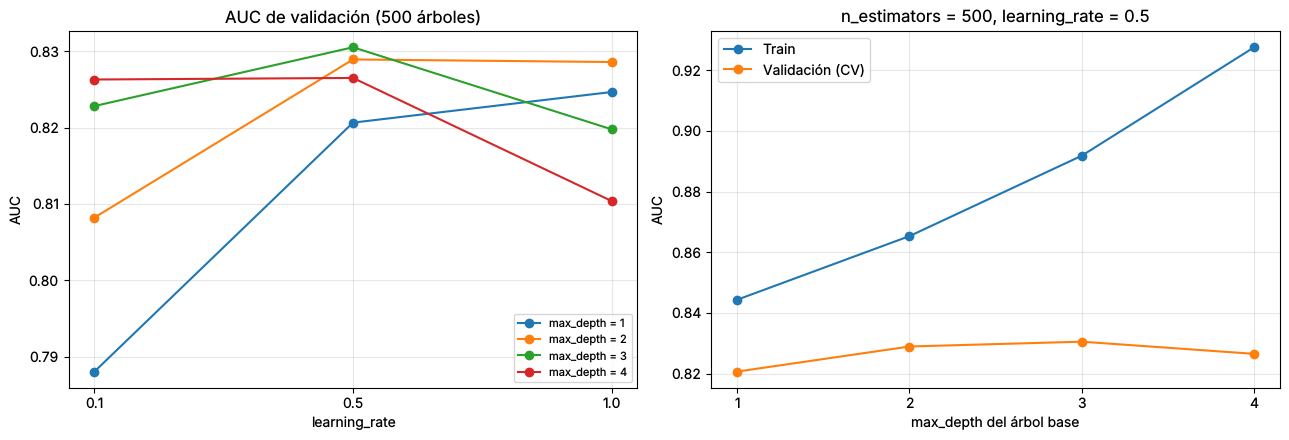

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: AUC de validación según learning_rate y profundidad (500 árboles)
sub = grilla_ada[grilla_ada['n_estimators'] == 500]
for max_depth in GRILLA_ADA['max_depth']:
    s = sub[sub['max_depth'] == max_depth].sort_values('learning_rate')
    axes[0].plot(s['learning_rate'].astype(str), s['auc'], 'o-', label=f'max_depth = {max_depth}')
axes[0].set_title('AUC de validación (500 árboles)')
axes[0].set_xlabel('learning_rate')
axes[0].legend(fontsize=8)

# Derecha: train vs validación según profundidad, con la mejor combinación de n_estimators y learning_rate
mejor_ada = grilla_ada.iloc[0]
s = grilla_ada[(grilla_ada['n_estimators'] == mejor_ada['n_estimators']) &
               (grilla_ada['learning_rate'] == mejor_ada['learning_rate'])].sort_values('max_depth')
axes[1].plot(s['max_depth'].astype(str), s['auc_train'], 'o-', label='Train')
axes[1].plot(s['max_depth'].astype(str), s['auc'], 'o-', label='Validación (CV)')
axes[1].set_title(f"n_estimators = {mejor_ada['n_estimators']}, learning_rate = {mejor_ada['learning_rate']}")
axes[1].set_xlabel('max_depth del árbol base')
axes[1].legend()

for ax in axes:
    ax.set_ylabel('AUC')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **Izquierda:** AUC de validación según `learning_rate` para cada profundidad, con 500 árboles. El mejor `learning_rate` depende de la profundidad del árbol base: con *stumps* (`max_depth = 1`) conviene el más alto (0,788 con 0,1 contra 0,825 con 1), porque cada árbol aporta muy poco y con votos chicos 500 árboles no alcanzan. Con árboles de profundidad 3 o 4 pasa lo contrario: con `learning_rate = 1` el AUC baja (0,820 y 0,810), porque árboles más complejos con voto completo se ajustan demasiado a las películas difíciles.
- **Derecha:** AUC en train y en validación según la profundidad del árbol base, con 500 árboles y `learning_rate = 0,5`. El train sube siempre (de 0,844 a 0,928), mientras que la validación mejora hasta profundidad 3 (0,831) y después baja (0,827). Es el comportamiento típico del sobreajuste, aunque mucho más suave que en el árbol solo.

Salvo con árboles de profundidad 4 y `learning_rate = 1`, agregar árboles da igual o mejor resultado dentro del rango probado, pero la ganancia entre 300 y 500 es mínima (0,001 en la mejor combinación).

### 4.4 Mejor configuración

In [6]:
print('Mejor AdaBoost:')
print(f"  max_depth={mejor_ada['max_depth']}, n_estimators={mejor_ada['n_estimators']}, learning_rate={mejor_ada['learning_rate']}")
print(f"  AUC validación = {mejor_ada['auc']:.3f} ± {mejor_ada['auc_std']:.3f}")
print(f"  AUC train      = {mejor_ada['auc_train']:.3f}  (diferencia {mejor_ada['auc_train'] - mejor_ada['auc']:.3f})")
print(f"  Mejora sobre el baseline: +{mejor_ada['auc'] - baseline_ada['auc']:.3f} de AUC")
empatadas = grilla_ada[grilla_ada['auc'] >= mejor_ada['auc'] - mejor_ada['auc_std']]
print(f"  Combinaciones dentro de un desvío del mejor: {len(empatadas)} de {len(grilla_ada)}")

Mejor AdaBoost:
  max_depth=3, n_estimators=500, learning_rate=0.5
  AUC validación = 0.831 ± 0.013
  AUC train      = 0.892  (diferencia 0.061)
  Mejora sobre el baseline: +0.028 de AUC
  Combinaciones dentro de un desvío del mejor: 21 de 36


**Elección:** árbol base de `max_depth=3`, `n_estimators=500`, `learning_rate=0.5`, con AUC de validación de 0,831 ± 0,013. A diferencia del Random Forest y de la regresión logística, acá el ajuste sí importa: la mejora sobre el baseline es de 0,028, más del doble del desvío entre folds. La principal diferencia la hacen los árboles base algo más profundos, que permiten capturar interacciones entre variables que los *stumps* no pueden.

Entre las combinaciones probadas, 21 de 36 quedan dentro de un desvío de la mejor, así que la elección exacta no es crítica. La diferencia entre train y validación (0,061) es moderada, bastante menor que la del Random Forest (0,136).

## 5. Gradient Boosting

**Gradient Boosting** también entrena árboles en secuencia, pero en lugar de cambiar los pesos de las películas, cada árbol nuevo se entrena para predecir **el error que todavía comete el modelo acumulado** (técnicamente, el gradiente de la función de pérdida, la *log-loss* en clasificación). La predicción se va corrigiendo de a poco: cada árbol suma una pequeña corrección, multiplicada por el `learning_rate`.

Además de la profundidad, la cantidad de árboles y el `learning_rate`, se ajusta `subsample`: la fracción de películas, tomada al azar, con la que se entrena cada árbol. Usar menos del 100% (*stochastic gradient boosting*) agrega azar, como en el Random Forest, y suele reducir el sobreajuste.

### 5.1 Baseline

Gradient Boosting con los hiperparámetros por defecto de sklearn: 100 árboles de profundidad 3, `learning_rate = 0.1` y `subsample = 1` (todas las películas).

In [7]:
baseline_gb = evaluar(GradientBoostingClassifier(random_state=SEED), X, y,
                      max_depth=3, n_estimators=100, learning_rate=0.1, subsample=1.0)

COLS_GB = ['max_depth', 'n_estimators', 'learning_rate', 'subsample',
           'auc', 'auc_std', 'auc_train', 'accuracy', 'precision', 'recall', 'f1']
pd.DataFrame([baseline_gb])[COLS_GB].round(3)

,max_depth,n_estimators,learning_rate,subsample,auc,auc_std,auc_train,accuracy,precision,recall,f1
0,3,100,0.1,1.0,0.832,0.012,0.904,0.752,0.772,0.708,0.738


Sin ajustar nada, Gradient Boosting alcanza un **AUC de 0,832 en validación con 0,904 en train**. Ya con los valores por defecto supera a todos los modelos anteriores, incluido el Random Forest ajustado (0,825), y queda a la par del AdaBoost ajustado (0,831).

### 5.2 Búsqueda de hiperparámetros (grid search)

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| `max_depth` | 2, 3, 4, 5 | Complejidad de cada árbol. |
| `n_estimators` | 100, 300, 500 | Cantidad de árboles de la secuencia. |
| `learning_rate` | 0.01, 0.05, 0.1 | Tamaño de la corrección que suma cada árbol. |
| `subsample` | 0.8, 1 | Fracción de películas con la que se entrena cada árbol. |

Son 4 × 3 × 3 × 2 = **72 combinaciones** con la misma CV de 5 folds. La tabla completa se guarda en `resultados/Boosting/gradient_boosting_grilla.csv`. La celda tarda unos minutos.

In [8]:
def crear_gb(max_depth, n_estimators, learning_rate, subsample):
    return GradientBoostingClassifier(max_depth=int(max_depth), n_estimators=int(n_estimators),
                                      learning_rate=float(learning_rate), subsample=float(subsample),
                                      random_state=SEED)

GRILLA_GB = {
    'max_depth': [2, 3, 4, 5],
    'n_estimators': [100, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

filas = []
for max_depth, n_estimators, learning_rate, subsample in itertools.product(*GRILLA_GB.values()):
    filas.append(evaluar(crear_gb(max_depth, n_estimators, learning_rate, subsample), X, y,
                         max_depth=max_depth, n_estimators=n_estimators,
                         learning_rate=learning_rate, subsample=subsample))

grilla_gb = pd.DataFrame(filas).sort_values('auc', ascending=False).reset_index(drop=True)
grilla_gb.to_csv(f'{CARPETA_RESULTADOS}/gradient_boosting_grilla.csv', index=False)
print(f'{len(grilla_gb)} combinaciones evaluadas')

72 combinaciones evaluadas


**Las 10 mejores combinaciones** (ordenadas por AUC de validación), comparadas con el baseline:

In [9]:
top10_gb = grilla_gb.head(10)[COLS_GB].copy()
top10_gb.index = range(1, 11)
top10_gb.loc['baseline'] = pd.Series(baseline_gb)[COLS_GB]
top10_gb.round(3)

,max_depth,n_estimators,learning_rate,subsample,auc,auc_std,auc_train,accuracy,precision,recall,f1
1,3,300,0.05,0.8,0.836,0.013,0.926,0.752,0.766,0.715,0.740
2,4,300,0.05,0.8,0.835,0.012,0.968,0.752,0.768,0.715,0.740
3,3,100,0.10,0.8,0.835,0.009,0.905,0.756,0.776,0.712,0.742
4,2,500,0.05,0.8,0.835,0.010,0.899,0.754,0.772,0.711,0.740
5,5,500,0.01,0.8,0.834,0.011,0.949,0.753,0.772,0.708,0.739
6,2,500,0.05,1.0,0.834,0.009,0.895,0.751,0.770,0.709,0.738
7,3,300,0.05,1.0,0.834,0.013,0.922,0.752,0.768,0.713,0.739
8,2,300,0.10,1.0,0.834,0.010,0.903,0.748,0.766,0.705,0.734
9,4,100,0.10,0.8,0.834,0.012,0.946,0.754,0.773,0.712,0.741
10,4,500,0.01,0.8,0.834,0.011,0.914,0.750,0.771,0.702,0.735


### 5.3 Efecto de los hiperparámetros

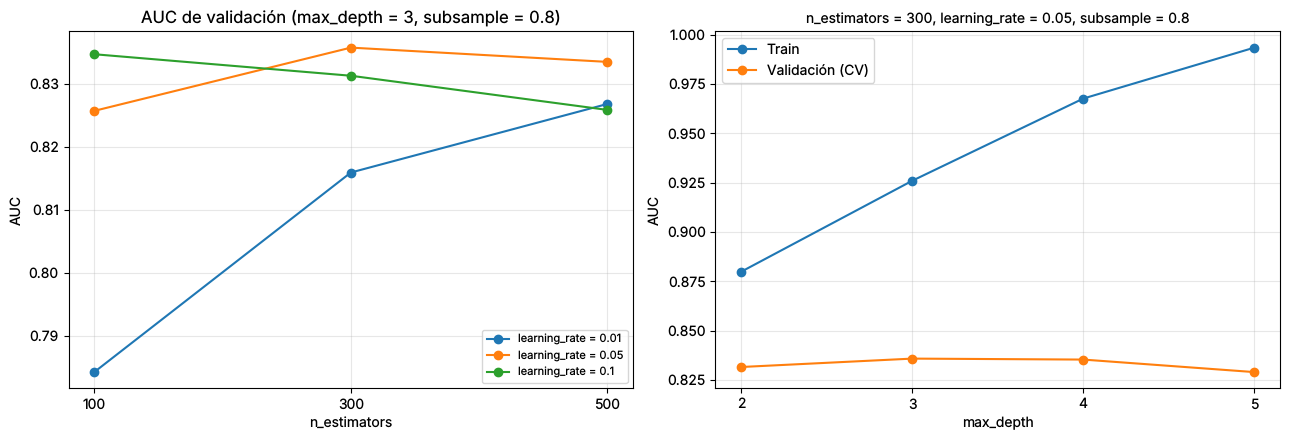

subsample = 0.8 mejora el AUC en 33 de 36 combinaciones (diferencia promedio +0.0027)


In [10]:
mejor_gb = grilla_gb.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: AUC de validación según n_estimators para cada learning_rate (profundidad y subsample del mejor)
sub = grilla_gb[(grilla_gb['max_depth'] == mejor_gb['max_depth']) & (grilla_gb['subsample'] == mejor_gb['subsample'])]
for learning_rate in GRILLA_GB['learning_rate']:
    s = sub[sub['learning_rate'] == learning_rate].sort_values('n_estimators')
    axes[0].plot(s['n_estimators'].astype(str), s['auc'], 'o-', label=f'learning_rate = {learning_rate}')
axes[0].set_title(f"AUC de validación (max_depth = {mejor_gb['max_depth']}, subsample = {mejor_gb['subsample']})")
axes[0].set_xlabel('n_estimators')
axes[0].legend(fontsize=8)

# Derecha: train vs validación según profundidad (resto de los hiperparámetros como el mejor)
s = grilla_gb[(grilla_gb['n_estimators'] == mejor_gb['n_estimators']) &
              (grilla_gb['learning_rate'] == mejor_gb['learning_rate']) &
              (grilla_gb['subsample'] == mejor_gb['subsample'])].sort_values('max_depth')
axes[1].plot(s['max_depth'].astype(str), s['auc_train'], 'o-', label='Train')
axes[1].plot(s['max_depth'].astype(str), s['auc'], 'o-', label='Validación (CV)')
axes[1].set_title(f"n_estimators = {mejor_gb['n_estimators']}, learning_rate = {mejor_gb['learning_rate']}, "
                  f"subsample = {mejor_gb['subsample']}", fontsize=10)
axes[1].set_xlabel('max_depth')
axes[1].legend()

for ax in axes:
    ax.set_ylabel('AUC')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Efecto de subsample: misma combinación con 0.8 y con 1
pares = grilla_gb.pivot_table(index=['max_depth', 'n_estimators', 'learning_rate'], columns='subsample', values='auc')
print(f"subsample = 0.8 mejora el AUC en {(pares[0.8] > pares[1.0]).sum()} de {len(pares)} combinaciones "
      f"(diferencia promedio {(pares[0.8] - pares[1.0]).mean():+.4f})")

- **Izquierda:** AUC de validación según la cantidad de árboles para cada `learning_rate`, con `max_depth = 3` y `subsample = 0,8`. Se ve el compromiso entre los dos hiperparámetros: con `learning_rate = 0,01` el modelo aprende despacio y con 500 árboles todavía sigue mejorando (0,784 → 0,827); con 0,05 llega al máximo cerca de los 300 árboles (0,836) y después baja apenas; con 0,1 el máximo se alcanza con 100 árboles (0,835) y agregar más empeora el resultado (0,826 con 500). A diferencia del Random Forest, en boosting más árboles **sí** pueden sobreajustar.
- **Derecha:** AUC en train y en validación según `max_depth`, con el resto de los hiperparámetros como en la mejor combinación. El train sube de 0,880 a 0,993, mientras que la validación se mantiene entre 0,829 y 0,836, con el máximo en profundidad 3. Los árboles más profundos memorizan el train sin mejorar la generalización.
- **`subsample`:** entrenar cada árbol con el 80% de las películas mejora el AUC en 33 de las 36 combinaciones, aunque por muy poco (0,003 en promedio).

### 5.4 Mejor configuración

In [11]:
print('Mejor Gradient Boosting:')
print(f"  max_depth={mejor_gb['max_depth']}, n_estimators={mejor_gb['n_estimators']}, "
      f"learning_rate={mejor_gb['learning_rate']}, subsample={mejor_gb['subsample']}")
print(f"  AUC validación = {mejor_gb['auc']:.3f} ± {mejor_gb['auc_std']:.3f}")
print(f"  AUC train      = {mejor_gb['auc_train']:.3f}  (diferencia {mejor_gb['auc_train'] - mejor_gb['auc']:.3f})")
print(f"  Mejora sobre el baseline: +{mejor_gb['auc'] - baseline_gb['auc']:.3f} de AUC")
empatadas = grilla_gb[grilla_gb['auc'] >= mejor_gb['auc'] - mejor_gb['auc_std']]
print(f"  Combinaciones dentro de un desvío del mejor: {len(empatadas)} de {len(grilla_gb)}")

Mejor Gradient Boosting:
  max_depth=3, n_estimators=300, learning_rate=0.05, subsample=0.8
  AUC validación = 0.836 ± 0.013
  AUC train      = 0.926  (diferencia 0.090)
  Mejora sobre el baseline: +0.004 de AUC
  Combinaciones dentro de un desvío del mejor: 46 de 72


**Elección:** `max_depth=3`, `n_estimators=300`, `learning_rate=0.05`, `subsample=0.8`, con AUC de validación de 0,836 ± 0,013. La mejora sobre el baseline es de solo 0,004, menor al desvío entre folds: 46 de las 72 combinaciones quedan dentro de un desvío de la mejor. Los valores por defecto de sklearn ya estaban cerca del óptimo, y lo que se observa en la grilla es que muchas combinaciones distintas de profundidad, cantidad de árboles y `learning_rate` llegan al mismo techo de 0,83 a 0,836.

Entre las combinaciones empatadas hay opciones con menor diferencia entre train y validación (por ejemplo, `max_depth=2` con 500 árboles: 0,835 con 0,899 en train). Se mantiene la de mayor AUC de validación, como en los otros modelos; la diferencia de 0,090 es menor que la del Random Forest (0,136).

## 6. Comparación entre AdaBoost y Gradient Boosting

Se comparan las dos variantes (baseline y ajustada) junto con los modelos de las notebooks anteriores, leídos de sus archivos en `resultados/`. Todos usan los mismos folds, así que los números son directamente comparables.

In [12]:
def leer_final(ruta):
    # En Colab no está la carpeta resultados: se lee del repo
    if not os.path.exists(ruta):
        ruta = 'https://raw.githubusercontent.com/juanmareolon/OBL_ML/main/' + ruta
    return pd.read_csv(ruta).iloc[0]

def fila(nombre, r):
    return {'modelo': nombre, 'auc_cv': r['auc'], 'auc_cv_std': r['auc_std'], 'auc_train': r['auc_train'],
            'accuracy': r['accuracy'], 'precision': r['precision'], 'recall': r['recall'], 'f1': r['f1']}

filas = [fila('AdaBoost (baseline)', baseline_ada), fila('AdaBoost (ajustado)', mejor_ada),
         fila('Gradient Boosting (baseline)', baseline_gb), fila('Gradient Boosting (ajustado)', mejor_gb)]
for ruta in ['resultados/Arbol_Clasificacion/arbol_final.csv',
             'resultados/Regresion_Logistica/logistica_final.csv',
             'resultados/Random_Forest/random_forest_final.csv']:
    r = leer_final(ruta)
    filas.append({c: r[c] for c in ['modelo', 'auc_cv', 'auc_cv_std', 'auc_train',
                                    'accuracy', 'precision', 'recall', 'f1']})

comparacion_modelos = pd.DataFrame(filas).set_index('modelo')
comparacion_modelos.round(3)

,auc_cv,auc_cv_std,auc_train,accuracy,precision,recall,f1
modelo,,,,,,,
AdaBoost (baseline),0.802,0.003,0.821,0.726,0.739,0.688,0.712
AdaBoost (ajustado),0.831,0.013,0.892,0.751,0.763,0.719,0.740
Gradient Boosting (baseline),0.832,0.012,0.904,0.752,0.772,0.708,0.738
Gradient Boosting (ajustado),0.836,0.013,0.926,0.752,0.766,0.715,0.740
Árbol de clasificación,0.769,0.013,0.813,0.697,0.705,0.669,0.685
Regresión logística,0.815,0.009,0.821,0.744,0.751,0.721,0.736
Random Forest,0.825,0.011,0.960,0.743,0.761,0.698,0.728


Para ver si la diferencia entre AdaBoost y Gradient Boosting es consistente y no producto de un fold en particular, se compara el AUC de ambos fold por fold (los folds son los mismos):

In [13]:
from sklearn.model_selection import cross_validate

modelo_ada = crear_adaboost(mejor_ada['max_depth'], mejor_ada['n_estimators'], mejor_ada['learning_rate'])
modelo_gb = crear_gb(mejor_gb['max_depth'], mejor_gb['n_estimators'], mejor_gb['learning_rate'], mejor_gb['subsample'])

auc_por_fold = pd.DataFrame({
    nombre: cross_validate(crear_pipeline(m), X, y, cv=crear_cv(), scoring='roc_auc', n_jobs=-1)['test_score']
    for nombre, m in [('AdaBoost', modelo_ada), ('Gradient Boosting', modelo_gb)]
}, index=[f'fold {i}' for i in range(1, N_FOLDS + 1)])
auc_por_fold['diferencia'] = auc_por_fold['Gradient Boosting'] - auc_por_fold['AdaBoost']
print(f"Gradient Boosting supera a AdaBoost en {(auc_por_fold['diferencia'] > 0).sum()} de {N_FOLDS} folds")
auc_por_fold.round(3)

Gradient Boosting supera a AdaBoost en 5 de 5 folds


,AdaBoost,Gradient Boosting,diferencia
fold 1,0.845,0.846,0.000
fold 2,0.832,0.843,0.012
fold 3,0.843,0.848,0.005
fold 4,0.813,0.818,0.005
fold 5,0.820,0.824,0.004


**Lectura:**

- **Gradient Boosting es el mejor modelo hasta ahora**, con 0,836 de AUC en validación, seguido por AdaBoost (0,831) y Random Forest (0,825). Las dos variantes de boosting superan a los modelos anteriores.
- La diferencia entre Gradient Boosting y AdaBoost es chica (0,005, menor al desvío entre folds de 0,013), pero es **consistente**: Gradient Boosting gana en los 5 folds, por entre 0,000 y 0,012. El desvío entre folds refleja sobre todo que algunos folds son más difíciles que otros para todos los modelos (el fold 4 es el peor para ambos), no que el orden entre modelos cambie.
- La mayor diferencia entre ambos está en el punto de partida: AdaBoost necesita ajuste para rendir (de 0,802 a 0,831), mientras que Gradient Boosting ya funciona bien con los valores por defecto (0,832).
- En las métricas con umbral de 0,5 (accuracy, precision, recall, F1) los dos son prácticamente iguales. Ambos mejoran la accuracy del Random Forest y de la regresión logística (0,75 contra 0,74).

## 7. Análisis del modelo elegido

Se elige **Gradient Boosting** por tener el mayor AUC de validación y superar a AdaBoost en todos los folds. En esta sección se analiza en detalle: evolución del AUC a lo largo de la secuencia de árboles, matriz de confusión e importancia de variables. De AdaBoost se genera igualmente la submission para Kaggle (sección 8).

### 7.1 AUC según la cantidad de árboles

Gradient Boosting permite obtener la predicción del modelo después de cada árbol (`staged_predict_proba`), así que en cada fold se puede medir el AUC del modelo con 1, 2, ..., `n_estimators` árboles sin reentrenar. Esto muestra cómo evoluciona el ajuste a lo largo de la secuencia y si la cantidad elegida es razonable.

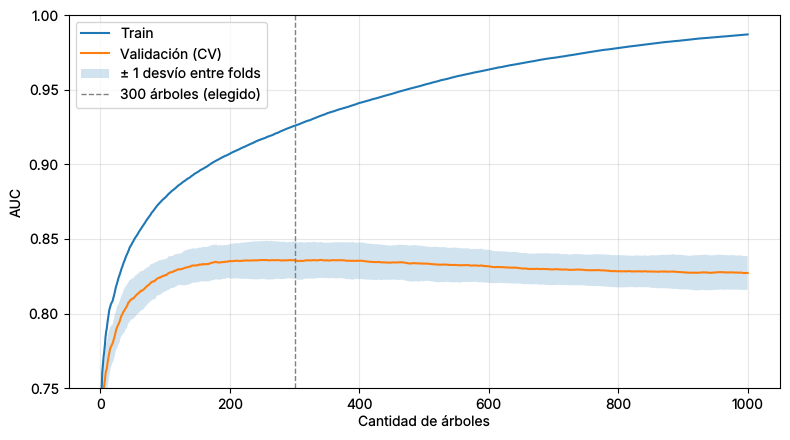

Máximo AUC de validación: 0.836 con 341 árboles
   100 árboles: validación 0.826 | train 0.878
   300 árboles: validación 0.836 | train 0.926
   500 árboles: validación 0.834 | train 0.953
  1000 árboles: validación 0.827 | train 0.987


In [14]:
from sklearn.metrics import roc_auc_score

N_MAX = 1000  # se extiende la curva más allá de la grilla para ver qué pasa con más árboles
modelo_curva = crear_gb(mejor_gb['max_depth'], N_MAX, mejor_gb['learning_rate'], mejor_gb['subsample'])

curva_val, curva_train = [], []
for idx_train, idx_val in crear_cv().split(X, y):
    pipe = crear_pipeline(modelo_curva).fit(X.iloc[idx_train], y.iloc[idx_train])
    prep, gb = pipe.named_steps['prep'], pipe.named_steps['modelo']
    Xtr, Xva = prep.transform(X.iloc[idx_train]), prep.transform(X.iloc[idx_val])
    curva_train.append([roc_auc_score(y.iloc[idx_train], p[:, 1]) for p in gb.staged_predict_proba(Xtr)])
    curva_val.append([roc_auc_score(y.iloc[idx_val], p[:, 1]) for p in gb.staged_predict_proba(Xva)])

curva_val, curva_train = np.array(curva_val), np.array(curva_train)
arboles = np.arange(1, N_MAX + 1)
media_val, desvio_val = curva_val.mean(axis=0), curva_val.std(axis=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(arboles, curva_train.mean(axis=0), label='Train')
ax.plot(arboles, media_val, label='Validación (CV)')
ax.fill_between(arboles, media_val - desvio_val, media_val + desvio_val, alpha=0.2, label='± 1 desvío entre folds')
ax.axvline(mejor_gb['n_estimators'], color='gray', linestyle='--', linewidth=1,
           label=f"{mejor_gb['n_estimators']} árboles (elegido)")
ax.set_xlabel('Cantidad de árboles')
ax.set_ylabel('AUC')
ax.set_ylim(0.75, 1.0)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

mejor_n = int(arboles[media_val.argmax()])
print(f"Máximo AUC de validación: {media_val.max():.3f} con {mejor_n} árboles")
for n in [100, 300, 500, 1000]:
    print(f"  {n:>4} árboles: validación {media_val[n - 1]:.3f} | train {curva_train.mean(axis=0)[n - 1]:.3f}")

El AUC en train sube sin parar a medida que se agregan árboles (0,878 con 100, 0,987 con 1000): cada árbol nuevo corrige errores del train, incluso cuando lo que queda por corregir ya es ruido. En validación, en cambio, el AUC sube rápido al principio, llega a un máximo de 0,836 alrededor de los 340 árboles y después **baja lentamente** (0,834 con 500 y 0,827 con 1000).

Los 300 árboles elegidos en la grilla quedan prácticamente en el máximo de la curva, así que la cantidad es adecuada. El gráfico también muestra por qué en boosting la cantidad de árboles se ajusta junto con el `learning_rate`, a diferencia del Random Forest, donde agregar árboles nunca empeoraba el resultado.

### 7.2 Matriz de confusión

Cada película se predice con el modelo del fold en el que quedó en validación (o sea, con un modelo que no la vio al entrenar). Se usa el umbral por defecto de 0,5 sobre la probabilidad.

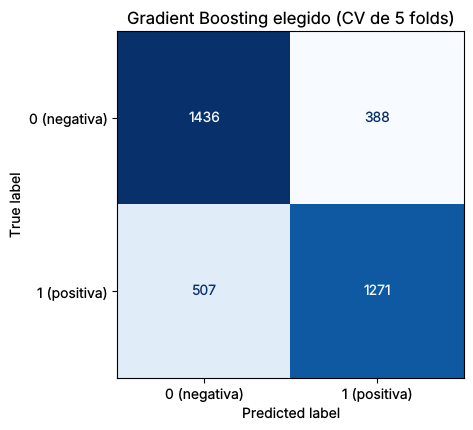

Verdaderos negativos: 1436  | Falsos positivos: 388
Falsos negativos:     507  | Verdaderos positivos: 1271
De las películas con opinión negativa, detecta el 79%
De las películas con opinión positiva, detecta el 71% (recall)
De las que predice como positivas, acierta el 77% (precision)


In [15]:
fig, ax = plt.subplots(figsize=(5, 4.5))
cm = matriz_confusion(modelo_gb, X, y, titulo='Gradient Boosting elegido (CV de 5 folds)', ax=ax)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Verdaderos negativos: {tn}  | Falsos positivos: {fp}')
print(f'Falsos negativos:     {fn}  | Verdaderos positivos: {tp}')
print(f'De las películas con opinión negativa, detecta el {tn / (tn + fp):.0%}')
print(f'De las películas con opinión positiva, detecta el {tp / (tp + fn):.0%} (recall)')
print(f'De las que predice como positivas, acierta el {tp / (tp + fp):.0%} (precision)')

Clasifica bien el 79% de las películas con opinión negativa y el 71% de las positivas. Respecto del Random Forest, acierta lo mismo en las negativas (388 falsos positivos contra 389) y detecta 30 positivas más (507 falsos negativos contra 537), por eso mejora el recall (0,715 contra 0,698) y la accuracy (0,752 contra 0,743). Igual que todos los modelos anteriores, se equivoca más con las positivas que con las negativas.

### 7.3 Importancia de variables

Se entrena el Gradient Boosting elegido con todo el train y se muestra su importancia de variables (reducción de impureza acumulada en todos los árboles, `feature_importances_`), junto con la del Random Forest elegido en `Random_Forest.ipynb` (`max_depth=15`, `min_samples_leaf=5`, `max_features=sqrt`, 300 árboles) para comparar.

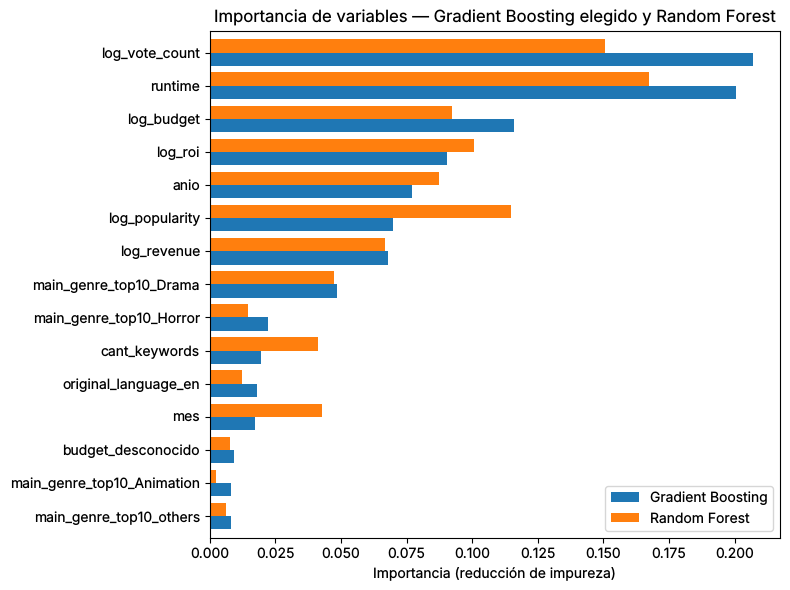

Variables con importancia mayor a 0: 26 de 27
Las 5 primeras concentran el 69% de la importancia (Random Forest: 63%)


,Gradient Boosting,Random Forest
log_vote_count,0.207,0.151
runtime,0.200,0.167
log_budget,0.116,0.092
log_roi,0.091,0.101
anio,0.077,0.087
log_popularity,0.070,0.115
log_revenue,0.068,0.067
main_genre_top10_Drama,0.048,0.047
main_genre_top10_Horror,0.022,0.014
cant_keywords,0.019,0.041


In [16]:
from sklearn.ensemble import RandomForestClassifier

pipe_gb = entrenar(modelo_gb, X, y)
nombres = pipe_gb.named_steps['prep'].get_feature_names_out()
importancias = (pd.Series(pipe_gb.named_steps['modelo'].feature_importances_, index=nombres)
                .sort_values(ascending=False))

pipe_rf = entrenar(RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=5,
                                          max_features='sqrt', random_state=SEED), X, y)
importancias_rf = pd.Series(pipe_rf.named_steps['modelo'].feature_importances_, index=nombres)

comparacion_imp = (pd.DataFrame({'Gradient Boosting': importancias, 'Random Forest': importancias_rf})
                   .loc[importancias.index].head(15))

fig, ax = plt.subplots(figsize=(8, 6))
comparacion_imp.iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set_title('Importancia de variables — Gradient Boosting elegido y Random Forest')
ax.set_xlabel('Importancia (reducción de impureza)')
plt.tight_layout()
plt.show()

print(f'Variables con importancia mayor a 0: {(importancias > 0).sum()} de {len(importancias)}')
print(f'Las 5 primeras concentran el {importancias.head(5).sum():.0%} de la importancia '
      f'(Random Forest: {importancias_rf.sort_values(ascending=False).head(5).sum():.0%})')
comparacion_imp.head(10).round(3)

**Lectura:**

- Las variables más importantes son las mismas que en el árbol y el Random Forest: cantidad de votos, duración, presupuesto y ROI. Los modelos basados en árboles y la regresión logística coinciden en que la cantidad de votos y la duración son lo que más información aporta sobre la opinión.
- La importancia está **algo más concentrada** que en el Random Forest: las 5 primeras variables suman el 69% (63% en el Random Forest), y votos y duración solas suman el 41%. En boosting cada árbol puede elegir entre todas las variables, así que usa las más informativas con más frecuencia; en el Random Forest, el sorteo de variables en cada división obliga a repartir.
- La popularidad pierde peso (0,070 contra 0,115 en el Random Forest). Está muy correlacionada con la cantidad de votos, y al poder elegir siempre entre las dos, el modelo se queda mayormente con los votos.
- Igual que en el Random Forest, esta medida no tiene signo y favorece a las variables numéricas frente a las binarias (géneros, idiomas, indicadores).

## 8. Submissions y resultados en Kaggle

Se entrena cada modelo con **todo** el train y se guardan las **probabilidades** de la clase 1 para las 1201 películas del test (no clases 0/1, porque la métrica de la competencia es AUC).

### 8.1 Modelos elegidos

Una submission por cada variante de boosting, con la mejor configuración de su grilla:

- `kaggle/submission_adaboost.csv`
- `kaggle/submission_gradient_boosting.csv`

In [17]:
sub_ada = generar_submission(modelo_ada, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_adaboost.csv')
sub_gb = generar_submission(modelo_gb, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_gradient_boosting.csv')

# Chequeos: 1201 filas, sin NaN y probabilidades (no solo 0/1)
for nombre, sub in [('AdaBoost', sub_ada), ('Gradient Boosting', sub_gb)]:
    assert len(sub) == len(X_test) and sub['opinion'].notna().all()
    print(f"{nombre}: probabilidades entre {sub['opinion'].min():.3f} y {sub['opinion'].max():.3f}, "
          f"{sub['opinion'].nunique()} valores distintos")
print(f"Correlación entre las dos submissions: {sub_ada['opinion'].corr(sub_gb['opinion']):.3f}")

Guardado kaggle/submission_adaboost.csv (1201 filas)


Guardado kaggle/submission_gradient_boosting.csv (1201 filas)
AdaBoost: probabilidades entre 0.238 y 0.779, 1187 valores distintos
Gradient Boosting: probabilidades entre 0.027 y 0.997, 1201 valores distintos
Correlación entre las dos submissions: 0.920


Las probabilidades de AdaBoost quedan concentradas cerca de 0,5 porque surgen de una votación ponderada de árboles, mientras que las de Gradient Boosting cubren casi todo el rango de 0 a 1. Esto no afecta al AUC, que solo depende del orden en que quedan las películas y no del valor de la probabilidad.

### 8.2 Variantes más simples

En las dos grillas hay varias combinaciones prácticamente empatadas con la mejor. Para ver si una configuración más simple generaliza igual o mejor en el test, se sube una segunda submission de cada modelo, elegida con esta regla: entre las combinaciones que quedan a menos de 0,002 de AUC de validación de la mejor, la de **menor diferencia entre train y validación** (la que menos sobreajusta).

La regla se define antes de ver los resultados de Kaggle y usa solo la validación cruzada.

In [18]:
MARGEN = 0.002

def variante_simple(grilla):
    # Entre las casi empatadas con la mejor (sin contarla), la de menor diferencia train - validación
    cerca = grilla[grilla['auc'] >= grilla['auc'].max() - MARGEN].iloc[1:]
    cerca = cerca.assign(diferencia_train_val=cerca['auc_train'] - cerca['auc'])
    return cerca.sort_values('diferencia_train_val').iloc[0]

ada_2 = variante_simple(grilla_ada)
gb_2 = variante_simple(grilla_gb)

modelo_ada_2 = crear_adaboost(ada_2['max_depth'], ada_2['n_estimators'], ada_2['learning_rate'])
modelo_gb_2 = crear_gb(gb_2['max_depth'], gb_2['n_estimators'], gb_2['learning_rate'], gb_2['subsample'])

sub_ada_2 = generar_submission(modelo_ada_2, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_adaboost_2.csv')
sub_gb_2 = generar_submission(modelo_gb_2, X, y, X_test, ids_test, f'{CARPETA_KAGGLE}/submission_gradient_boosting_2.csv')
print(f"Correlación con la submission del modelo elegido: AdaBoost {sub_ada['opinion'].corr(sub_ada_2['opinion']):.3f}, "
      f"Gradient Boosting {sub_gb['opinion'].corr(sub_gb_2['opinion']):.3f}")

cols = ['max_depth', 'n_estimators', 'learning_rate', 'subsample', 'auc', 'auc_std', 'auc_train']
variantes = pd.DataFrame([mejor_ada, ada_2, mejor_gb, gb_2],
                         index=['AdaBoost (elegido)', 'AdaBoost (variante simple)',
                                'Gradient Boosting (elegido)', 'Gradient Boosting (variante simple)'])[cols]
variantes['diferencia_train_val'] = variantes['auc_train'] - variantes['auc']
variantes.round(3)

Guardado kaggle/submission_adaboost_2.csv (1201 filas)


Guardado kaggle/submission_gradient_boosting_2.csv (1201 filas)
Correlación con la submission del modelo elegido: AdaBoost 0.974, Gradient Boosting 0.986


,max_depth,n_estimators,learning_rate,subsample,auc,auc_std,auc_train,diferencia_train_val
AdaBoost (elegido),3,500,0.50,NaN,0.831,0.013,0.892,0.061
AdaBoost (variante simple),2,500,0.50,NaN,0.829,0.010,0.865,0.036
Gradient Boosting (elegido),3,300,0.05,0.8,0.836,0.013,0.926,0.090
Gradient Boosting (variante simple),2,500,0.05,1.0,0.834,0.009,0.895,0.061


Con esa regla, las dos variantes usan árboles de profundidad 2 en lugar de 3, con 500 árboles: AdaBoost con `learning_rate = 0,5` (AUC de validación 0,829, diferencia con train de 0,036 contra 0,061 del elegido) y Gradient Boosting con `learning_rate = 0,05` y `subsample = 1` (0,834, diferencia de 0,061 contra 0,090). En validación son indistinguibles de los modelos elegidos, pero se ajustan menos al train.

Las predicciones son muy parecidas a las de los modelos elegidos (correlación de 0,97 y 0,99), así que se espera un puntaje de Kaggle similar.

### 8.3 Resultados en Kaggle

*Public Score* obtenido al subir cada archivo. Las filas de los modelos elegidos se guardan en `resultados/Boosting/adaboost_final.csv` y `resultados/Boosting/gradient_boosting_final.csv` para la tabla comparativa entre modelos, y las cuatro submissions en `resultados/Boosting/boosting_submissions.csv`.

In [19]:
auc_kaggle_ada = 0.83430   # Public Score de submission_adaboost.csv
auc_kaggle_gb = 0.84086    # Public Score de submission_gradient_boosting.csv
auc_kaggle_ada_2 = 0.83085 # Public Score de submission_adaboost_2.csv
auc_kaggle_gb_2 = 0.83999  # Public Score de submission_gradient_boosting_2.csv

def resultado(nombre, r, auc_kaggle):
    hiperparametros = (f"max_depth={r['max_depth']}, n_estimators={r['n_estimators']}, "
                       f"learning_rate={r['learning_rate']}")
    if 'subsample' in r.index and pd.notna(r['subsample']):
        hiperparametros += f", subsample={r['subsample']}"
    return {'modelo': nombre, 'hiperparametros': hiperparametros,
            'auc_cv': r['auc'], 'auc_cv_std': r['auc_std'], 'auc_train': r['auc_train'],
            'accuracy': r['accuracy'], 'precision': r['precision'], 'recall': r['recall'], 'f1': r['f1'],
            'auc_kaggle': auc_kaggle}

final_ada = resultado('AdaBoost', mejor_ada, auc_kaggle_ada)
final_gb = resultado('Gradient Boosting', mejor_gb, auc_kaggle_gb)
pd.DataFrame([final_ada]).to_csv(f'{CARPETA_RESULTADOS}/adaboost_final.csv', index=False)
pd.DataFrame([final_gb]).to_csv(f'{CARPETA_RESULTADOS}/gradient_boosting_final.csv', index=False)

submissions = pd.DataFrame([final_ada, resultado('AdaBoost (variante simple)', ada_2, auc_kaggle_ada_2),
                            final_gb, resultado('Gradient Boosting (variante simple)', gb_2, auc_kaggle_gb_2)])
submissions.to_csv(f'{CARPETA_RESULTADOS}/boosting_submissions.csv', index=False)
pd.set_option('display.max_colwidth', None)
submissions[['modelo', 'hiperparametros', 'auc_cv', 'auc_cv_std', 'auc_train', 'auc_kaggle']].round(4)

,modelo,hiperparametros,auc_cv,auc_cv_std,auc_train,auc_kaggle
0,AdaBoost,"max_depth=3, n_estimators=500, learning_rate=0.5",0.8305,0.0128,0.8919,0.8343
1,AdaBoost (variante simple),"max_depth=2, n_estimators=500, learning_rate=0.5",0.8289,0.0101,0.8653,0.8308
2,Gradient Boosting,"max_depth=3, n_estimators=300, learning_rate=0.05, subsample=0.8",0.8358,0.0125,0.9259,0.8409
3,Gradient Boosting (variante simple),"max_depth=2, n_estimators=500, learning_rate=0.05, subsample=1.0",0.8343,0.0090,0.8953,0.8400


**Interpretación:**

- Los dos modelos elegidos obtienen en Kaggle un puntaje algo mayor al de la validación cruzada: Gradient Boosting 0,841 (0,836 en CV) y AdaBoost 0,834 (0,831 en CV). Las diferencias (0,005 y 0,003) son menores al desvío entre folds (0,013), así que la validación cruzada resultó una buena estimación. Es esperable que el puntaje sea levemente mayor, porque el modelo final se entrena con todo el train (25% más de datos que en cada fold).
- El orden entre los dos se mantiene: Gradient Boosting supera a AdaBoost tanto en validación como en Kaggle.
- Respecto del Random Forest, el orden se invierte: en validación Gradient Boosting es mejor (0,836 contra 0,825), pero en Kaggle el Random Forest obtuvo 0,844. La diferencia en Kaggle es de 0,004, mucho menor que el desvío entre folds, y el puntaje público se calcula sobre un único conjunto de a lo sumo 1201 películas. Con diferencias de ese tamaño no se puede afirmar que un modelo sea mejor que el otro en el test; el criterio de elección sigue siendo la validación cruzada, que promedia 5 particiones.
- **Variantes simples:** obtienen un puntaje apenas menor que los modelos elegidos (Gradient Boosting 0,840 contra 0,841; AdaBoost 0,831 contra 0,834). Kaggle ordena las cuatro submissions igual que la validación cruzada, y todas quedan entre 0,002 y 0,006 por encima de su AUC de validación. Reducir la diferencia entre train y validación no mejoró la generalización: lo que predice el resultado en el test es el AUC de validación, no esa diferencia. Se mantienen los modelos elegidos en las secciones 4.4 y 5.4.